# Wo auf der Sonne Flares entstehen

Das Notebook verbindet die täglichen Ereignislisten des NOAA Space Weather Prediction Center (jeder Röntgenflare mit Klasse und aktiver Region) mit den täglichen Positionen der aktiven Regionen (Solar Region Summary), dreht jede Region mit der differentiellen Rotation auf den Zeitpunkt des Flares und erhält so die Positionen aller Flares eines Jahres (hier 2024). Daraus folgen die aktiven Breiten, der Anteil der Flares aus Regionen mit Delta-Flecken und ein Schmetterlingsdiagramm von 2016 bis 2026, an dem die Wanderung der Fleckenzonen zum Äquator gemessen wird; die Positionen werden mit den Hα-Positionen der Ereignislisten, mit SDO und mit HEK verglichen.

In welchen Breiten und in welchen aktiven Regionen entstehen Flares, und wie wandern diese Breiten im Lauf eines Zyklus?

#### **Hintergrund**

Sonnenflecken und Flares treten nicht überall auf der Sonne auf, sondern in zwei Gürteln nördlich und südlich des Äquators, meist zwischen 5° und 35° Breite. Zu Beginn eines Zyklus erscheinen die ersten Flecken bei etwa 25° bis 30°, im Lauf des Zyklus rücken die Gürtel zum Äquator (Spörersches Gesetz). Trägt man die Breite jeder Fleckengruppe gegen die Zeit auf, entsteht das Schmetterlingsdiagramm (Maunder 1904). Das Wandern zeigt, wo der Dynamo im Inneren gerade das stärkste toroidale Feld erzeugt.

NOAA nummeriert jede aktive Region fortlaufend (NOAA 13842 ist die 13 842. seit 1972) und beschreibt sie täglich in der Solar Region Summary (SRS): Position, Fläche, Fleckenzahl und magnetische Klasse nach dem Mount-Wilson-Schema. Dort bedeutet α eine einzelne Polarität, β zwei klar getrennte Polaritäten, γ eine gemischte Anordnung, und δ, dass Kernschatten (Umbren) entgegengesetzter Polarität im selben Halbschatten liegen, weniger als 2° voneinander entfernt. In δ-Regionen sind die Feldlinien stark verscherten und verdrillt; sie erzeugen einen großen Teil der starken Flares (Sammis, Tang & Zirin 2000).

Die Ereignislisten (Edited Events) enthalten jeden Röntgenflare der GOES-Satelliten (Typ XRA) mit Zeit, Klasse und Region, außerdem Beobachtungen im Licht der Hα-Linie (Typ FLA) mit eigener Position. Für die meisten großen Flares fehlt aber eine Hα-Position; die Region ist dagegen fast immer angegeben.

#### **Herleitung**

**1. Positionsangaben.** NOAA schreibt heliographische Positionen als Breite und Länge im Stonyhurst-System, zum Beispiel S15E06: 15° südlich des Äquators, 6° östlich des Zentralmeridians (von der Erde aus gesehen links). Mit Norden und Westen positiv ist das Breite $\varphi = -15°$ und Länge $\lambda = -6°$.

**2. Differentielle Rotation.** Die Sonne rotiert am Äquator schneller als in hohen Breiten. Für magnetische Strukturen gilt in Grad pro Tag (siderisch, gegen die Sterne)
$$\omega_{sid}(\varphi) = A + B\sin^2\varphi + C\sin^4\varphi, \qquad A = 14.713,\; B = -2.396,\; C = -1.787$$
(Howard, Harvey & Forgach 1990). Von der Erde aus gesehen ist die Rotation langsamer, weil die Erde in derselben Richtung um die Sonne läuft, im Mittel $360°/365.25\,\text{d} = 0.986°$ pro Tag:
$$\omega_{syn}(\varphi) = \omega_{sid}(\varphi) - 0.986°/\text{d} .$$
Am Äquator sind das 13.7° pro Tag, also 0.57° pro Stunde; bei 20° Breite 13.3° pro Tag. Die SRS gibt die Positionen für 00:00 UT an. Ein Flare um 12:18 UT liegt deshalb bei
$$\lambda_{\text{Flare}} = \lambda_{\text{SRS}} + \omega_{syn}(\varphi)\cdot\frac{12.3\,\text{h}}{24\,\text{h}} \approx \lambda_{\text{SRS}} + 7° .$$
Ohne diese Korrektur lägen die Flares eines Tages im Mittel um 6° bis 7° zu weit östlich.

**3. Von Breite und Länge zum Bild der Sonnenscheibe.** Das ist die Umkehrung der Formel aus `sun_sdo.ipynb`. Ein Punkt der Oberfläche mit Breite $\varphi$ und Länge $\lambda$ hat bei der Neigung $B_0$ der Rotationsachse zum Beobachter die Koordinaten (in Sonnenradien, $x$ nach Westen, $y$ nach Norden, $z$ zum Beobachter)
$$x = \cos\varphi\,\sin\lambda, \qquad y = \sin\varphi\cos B_0 - \cos\varphi\cos\lambda\,\sin B_0, \qquad z = \sin\varphi\sin B_0 + \cos\varphi\cos\lambda\cos B_0 .$$
Einsetzen in $\sin\varphi = y\cos B_0 + z\sin B_0$ gibt wieder $\sin\varphi$; der Punkt ist sichtbar, wenn $z > 0$. Mal dem scheinbaren Sonnenradius (etwa 960″) ergeben $x$ und $y$ die Bildkoordinaten $T_x$, $T_y$.

**4. Anreicherung in δ-Regionen.** Sei $p_\delta$ der Anteil aller Regionstage mit δ-Klasse und $q_\delta$ der Anteil der Flares, die aus einer δ-Region kommen. Wären Flares unabhängig von der magnetischen Klasse, wäre $q_\delta \approx p_\delta$. Das Verhältnis $q_\delta / p_\delta$ misst, wie viel häufiger δ-Regionen Flares erzeugen. Der statistische Fehler eines Anteils $q$ aus $n$ Flares ist $\sqrt{q(1-q)/n}$.

**5. Die Wanderung der Fleckenzonen.** Für die Breite neuer Regionen ab dem Minimum $t_{\min}$ nehmen wir ein exponentielles Gesetz an,
$$|\varphi|(t) = \varphi_0\,e^{-(t - t_{\min})/\tau} .$$
$\varphi_0$ ist die Breite zu Beginn des Zyklus, $\tau$ die Zeit, in der die Breite auf $1/e$ sinkt. Hathaway (2011) fand, dass ein solches Gesetz für alle Zyklen ähnlich gilt, wenn man die Zeit ab dem Beginn des Zyklus zählt.

#### **Daten**

NOAA SWPC veröffentlicht täglich zwei Textdateien, die NCEI seit 1996 archiviert:
- **Edited Events** (`YYYYMMDDevents.txt`): alle Ereignisse eines Tages, darunter die Röntgenflares (XRA) mit Beginn, Maximum, Ende, Klasse, integriertem Fluss und NOAA-Region sowie Hα-Flares (FLA) mit Position.
- **Solar Region Summary** (`YYYYMMDDSRS.txt`): alle aktiven Regionen mit Sonnenflecken, Position um 00:00 UT, Carrington-Länge, Fläche in Millionstel der Sonnenhalbkugel, Zürich-Klasse, Zahl der Flecken und magnetische Klasse.

Für das Jahr `YEAR` lädt das Notebook beide Dateien für jeden Tag (2 × 366 Dateien, 3.5 MB, beim ersten Lauf etwa eine Minute), für das Schmetterlingsdiagramm zusätzlich jede siebte SRS ab `BUTTERFLY_START` (rund 560 Dateien). Die Dateien landen in `astrodata/swpc`.

Die Heliophysics Event Knowledgebase (HEK) liefert Flare-Positionen direkt, war aber im Oktober 2026 nicht erreichbar. Schritt 6 versucht sie trotzdem und vergleicht, wenn sie antwortet.

In [1]:
# In Colab fehlen sunpy (mit den Teilen net, map, timeseries) und eine Bibliothek zum Lesen von NetCDF4;
# lokal ist meist alles da, und es wird nichts nachinstalliert
import importlib.util, subprocess, sys
missing = []
if importlib.util.find_spec("sunpy") is None:
    missing.append("sunpy[net,map,timeseries]")
if importlib.util.find_spec("netCDF4") is None and importlib.util.find_spec("h5netcdf") is None:
    missing.append("netCDF4")
if missing:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError(f"Es fehlt {', '.join(missing)}; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

In [2]:
import os
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis
# (astropy, sunpy). Das muss vor dem ersten Import von astropy und sunpy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
SUNPY_DIR = ASTRODATA / "sunpy"
for d in (ASTRODATA / "astropy", SUNPY_DIR, ASTRODATA / "goes"):
    d.mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)
(SUNPY_DIR / "sunpyrc").write_text(f"[general]\nworking_dir = {SUNPY_DIR}\n")
os.environ["SUNPY_CONFIGDIR"] = str(SUNPY_DIR)

import re, socket, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.time import Time
from sunpy.coordinates import sun

YEAR = 2024                              # Jahr für die Flare-Positionen
BUTTERFLY_START = "2016-01-01"           # Beginn des Schmetterlingsdiagramms (jede siebte SRS)
SWPC = ASTRODATA / "swpc"
SWPC.mkdir(exist_ok=True)
BASE = "https://www.ngdc.noaa.gov/stp/space-weather/swpc-products/daily_reports"

def fetch(kind, day):
    """Eine Tagesdatei laden (kind = 'events' oder 'SRS'); fehlt sie im Archiv, None."""
    sub = "solar_event_reports" if kind == "events" else "solar_region_summaries"
    path = SWPC / f"{day:%Y%m%d}{kind}.txt"
    if not path.exists():
        try:
            urllib.request.urlretrieve(f"{BASE}/{sub}/{day:%Y/%m}/{day:%Y%m%d}{kind}.txt", path)
        except Exception:
            return None
    return path

def fetch_many(kind, days):
    with ThreadPoolExecutor(8) as ex:                 # 8 Downloads gleichzeitig
        return list(ex.map(lambda d: fetch(kind, d), days))

LOC = re.compile(r"([NS])(\d\d)([EW])(\d\d)")
def parse_loc(s):
    """'S15E06' -> (-15, -6); Norden und Westen positiv."""
    m = LOC.fullmatch(s)
    if not m:
        return np.nan, np.nan
    return int(m[2]) * (1 if m[1] == "N" else -1), int(m[4]) * (1 if m[3] == "W" else -1)

def parse_events(path, day):
    rows = []
    for line in path.read_text(errors="replace").splitlines():
        if not re.match(r"^\s*\d+\s", line):
            continue
        tok = line.split()
        if tok[1] == "+":                             # '+' markiert ein Ereignis mit mehreren Beobachtungen
            tok.pop(1)
        if len(tok) < 8:
            continue
        rest = tok[7:]
        reg = int(rest[-1]) if len(rest) >= 3 and re.fullmatch(r"\d{4,5}", rest[-1]) else np.nan
        rows.append(dict(tag=day, ev=int(tok[0]), beginn=tok[1], maximum=tok[2], ende=tok[3], obs=tok[4],
                         typ=tok[6], rest=rest, reg=reg))
    return rows

def parse_srs(path, day):
    rows, inside = [], False
    for line in path.read_text(errors="replace").splitlines():
        if line.startswith("I.  Regions with Sunspots"):
            inside = True
            continue
        if line.startswith(("IA.", "II.")):
            break
        tok = line.split()
        if inside and len(tok) >= 8 and tok[0].isdigit():
            lat, lon = parse_loc(tok[1])
            rows.append(dict(tag=day, reg=int(tok[0]), lat=lat, lon=lon, carr=int(tok[2]), flaeche=int(tok[3]),
                             zurich=tok[4], n_flecken=int(tok[6]), mag=tok[7]))
    return rows

days = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31")
ev_paths, srs_paths = fetch_many("events", days), fetch_many("SRS", days)
events = pd.DataFrame([r for d, p in zip(days, ev_paths) if p for r in parse_events(p, d)])
srs = pd.DataFrame([r for d, p in zip(days, srs_paths) if p for r in parse_srs(p, d)])
wdays = pd.date_range(BUTTERFLY_START, pd.Timestamp.today() - pd.Timedelta(days=2), freq="7D")
srs_w = pd.DataFrame([r for d, p in zip(wdays, fetch_many("SRS", wdays)) if p for r in parse_srs(p, d)])

print(f"{YEAR}: {sum(p is not None for p in ev_paths)} Ereignislisten, {sum(p is not None for p in srs_paths)} SRS "
      f"(von {len(days)} Tagen)")
print(f"Ereignisse nach Typ: {events.typ.value_counts().head(6).to_dict()}")
print(f"SRS {YEAR}: {len(srs)} Regionstage, {srs.reg.nunique()} Regionen")
print(f"Schmetterlingsdiagramm: {srs_w.tag.nunique()} SRS von {srs_w.tag.min():%Y-%m-%d} bis {srs_w.tag.max():%Y-%m-%d}, "
      f"{srs_w.reg.nunique()} Regionen")

2024: 366 Ereignislisten, 365 SRS (von 366 Tagen)
Ereignisse nach Typ: {'RSP': 4355, 'FLA': 3801, 'XRA': 3766, 'RBR': 3766, 'DSF': 95, 'RNS': 76}
SRS 2024: 3102 Regionstage, 412 Regionen
Schmetterlingsdiagramm: 432 SRS von 2016-01-01 bis 2026-10-09, 1519 Regionen


#### **Reduktion**

##### *1. Röntgenflares und Regionen*

Wie viele Flares stehen in den Ereignislisten des Jahres, und bei wie vielen ist die aktive Region angegeben?

In [3]:
def flux(cls):
    try:
        return {"A": 1e-8, "B": 1e-7, "C": 1e-6, "M": 1e-5, "X": 1e-4}[cls[0]] * float(cls[1:])
    except (KeyError, ValueError, IndexError):
        return np.nan

def hours(s):
    m = re.search(r"\d{4}", s)                        # Vorsilben U, A, B (unsicher, nach, vor) ignorieren
    return int(m[0][:2]) + int(m[0][2:]) / 60 if m else np.nan

fl = events[events.typ == "XRA"].copy()
fl["klasse"] = fl.rest.str[1]
fl["F"] = fl.klasse.map(flux)
h = [hours(m) if "/" not in m else hours(b) for m, b in zip(fl.maximum, fl.beginn)]
fl["t_max"] = (fl.tag + pd.to_timedelta(h, unit="h")).dt.round("min")
fl["noaa"] = (fl.reg + 10000).astype("Int64")         # NOAA zählt seit 2002 über 10000, die Listen nur 4 Stellen
fl = fl.dropna(subset=["F"]).reset_index(drop=True)
counts = fl.klasse.str[0].value_counts()
print(f"{len(fl)} Röntgenflares: " + ", ".join(f"{c} {counts.get(c, 0)}" for c in "BCMX"))
print(f"Ohne Regionsangabe: {fl.reg.isna().mean():.1%} (Klasse M und X: {fl[fl.F >= 1e-5].reg.isna().mean():.1%})")
print(f"Davon von GOES-16: {(fl.obs == 'G16').mean():.0%}, GOES-18: {(fl.obs == 'G18').mean():.0%}")
print("\nDie zehn stärksten Flares:")
print(fl.nlargest(10, "F")[["t_max", "klasse", "noaa"]].to_string(index=False))

3766 Röntgenflares: B 35, C 2794, M 883, X 54
Ohne Regionsangabe: 8.6% (Klasse M und X: 4.5%)
Davon von GOES-16: 95%, GOES-18: 5%

Die zehn stärksten Flares:
              t_max klasse  noaa
2024-10-03 12:18:00   X9.0 13842
2024-05-14 16:51:00   X8.7 13664
2024-10-01 22:20:00   X7.1 13842
2024-02-22 22:34:00   X6.3 13590
2024-05-11 01:23:00   X5.8 13664
2024-05-06 06:35:00   X4.5 13663
2024-09-14 15:29:00   X4.5 13825
2024-05-10 06:54:00   X3.9 13664
2024-02-09 13:14:00   X3.3 13575
2024-10-24 03:57:00   X3.3 13869


#### **Eigene Messung**

##### *2. Die Position jedes Flares*

Wo lag jeder Flare auf der Sonnenscheibe, wenn man die Position seiner Region mit der differentiellen Rotation auf den Zeitpunkt des Maximums dreht?

quelle
SRS desselben Tages        3095
keine Region                325
SRS des Folgetags           259
Region nicht in der SRS      63
SRS des Vortags              24



Position bestimmt für 89.7% der Flares; davon hinter dem Rand (z < 0): 118, davon 115 am Westrand (Region schon hinter dem Rand, Flare noch sichtbar)
Stärkster Flare X9.0 am 2024-10-03 12:18 in NOAA 13842: SRS S15E06 um 00 UT → gedreht S15W01 (+6.9°), Tx = 15″, Ty = -353″


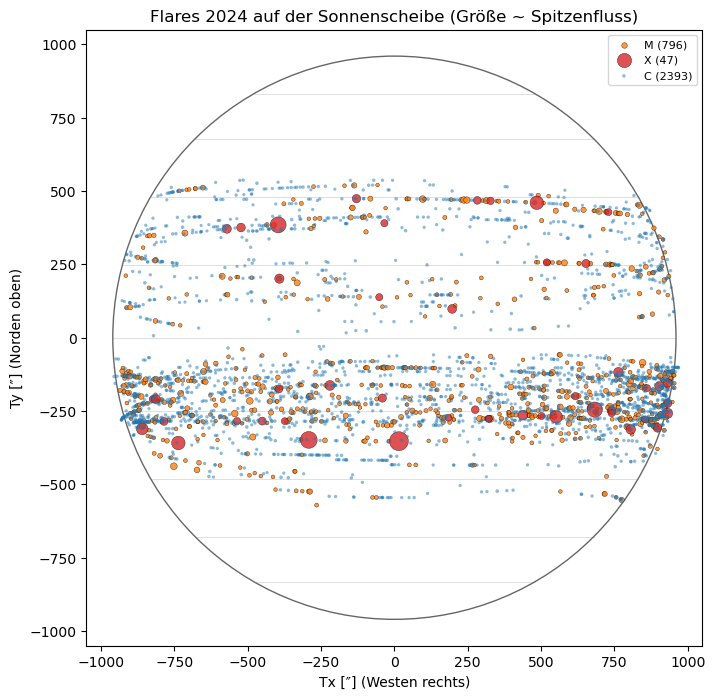

In [4]:
A_ROT, B_ROT, C_ROT, EARTH = 14.713, -2.396, -1.787, 360 / 365.25

def omega_syn(lat):
    s2 = np.sin(np.radians(lat)) ** 2
    return A_ROT + B_ROT * s2 + C_ROT * s2 ** 2 - EARTH

idx = srs.drop_duplicates(["tag", "reg"]).set_index(["tag", "reg"])
pos = []
for _, r in fl.iterrows():
    hit = None
    if not np.isnan(r.reg):
        for shift, source in ((0, "SRS desselben Tages"), (1, "SRS des Folgetags"), (-1, "SRS des Vortags")):
            key = (r.tag + pd.Timedelta(days=shift), int(r.reg))
            if key in idx.index:
                s = idx.loc[key]
                dt = (r.t_max - key[0]).total_seconds() / 86400          # Tage seit 00:00 UT der SRS
                hit = (s.lat, s.lon + omega_syn(s.lat) * dt, s.lon, s.mag, s.flaeche, source)
                break
    pos.append(hit if hit else (np.nan, np.nan, np.nan, None, np.nan,
                                "keine Region" if np.isnan(r.reg) else "Region nicht in der SRS"))
fl[["lat", "lon", "lon_srs", "mag", "flaeche", "quelle"]] = pd.DataFrame(pos, index=fl.index)
print(fl.quelle.value_counts().to_string())

# Bildkoordinaten mit B0 und scheinbarem Sonnenradius zum Zeitpunkt jedes Flares
ok = fl.lat.notna()
tt = Time(list(fl.t_max[ok]))
B0 = sun.B0(tt).to_value("rad")
R_as = sun.angular_radius(tt).to_value("arcsec")
phi, lam = np.radians(fl.lat[ok]), np.radians(fl.lon[ok])
fl.loc[ok, "Tx"] = R_as * np.cos(phi) * np.sin(lam)
fl.loc[ok, "Ty"] = R_as * (np.sin(phi) * np.cos(B0) - np.cos(phi) * np.cos(lam) * np.sin(B0))
fl.loc[ok, "z"] = np.sin(phi) * np.sin(B0) + np.cos(phi) * np.cos(lam) * np.cos(B0)
behind = fl.z < 0
print(f"\nPosition bestimmt für {ok.mean():.1%} der Flares; davon hinter dem Rand (z < 0): {behind.sum()}, "
      f"davon {(behind & (fl.lon > 0)).sum()} am Westrand (Region schon hinter dem Rand, Flare noch sichtbar)")

def label_ns(lat, lon):
    return f"{'N' if lat >= 0 else 'S'}{abs(lat):02.0f}{'W' if lon >= 0 else 'E'}{abs(lon):02.0f}"
ex = fl.loc[fl.F.idxmax()]
print(f"Stärkster Flare {ex.klasse} am {ex.t_max:%Y-%m-%d %H:%M} in NOAA {ex.noaa}: SRS {label_ns(ex.lat, ex.lon_srs)} um 00 UT "
      f"→ gedreht {label_ns(ex.lat, ex.lon)} ({ex.lon - ex.lon_srs:+.1f}°), Tx = {ex.Tx:.0f}″, Ty = {ex.Ty:.0f}″")

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 960, fill=False, color="0.4"))
for lat0 in range(-60, 61, 15):                       # Breitenkreise für B0 = 0 zur Orientierung
    th = np.radians(np.linspace(-90, 90, 100))
    ax.plot(960 * np.cos(np.radians(lat0)) * np.sin(th), np.full_like(th, 960 * np.sin(np.radians(lat0))),
            c="0.85", lw=0.6, zorder=0)
for lo, hi, col, name in ((1e-5, 1e-4, "tab:orange", "M"), (1e-4, 1, "tab:red", "X"), (1e-6, 1e-5, "tab:blue", "C")):
    s = fl[(fl.F >= lo) & (fl.F < hi) & (fl.z > 0)]
    ax.scatter(s.Tx, s.Ty, s=5 + 2e5 * s.F, c=col, alpha=0.5 if name == "C" else 0.8,
               edgecolor="k" if name != "C" else "none", lw=0.3, label=f"{name} ({len(s)})")
ax.set_aspect("equal")
ax.set_xlim(-1050, 1050)
ax.set_ylim(-1050, 1050)
ax.set_xlabel("Tx [″] (Westen rechts)")
ax.set_ylabel("Ty [″] (Norden oben)")
ax.set_title(f"Flares {YEAR} auf der Sonnenscheibe (Größe ~ Spitzenfluss)")
ax.legend(fontsize=8, loc="upper right")
plt.show()

##### *3. Die aktiven Breiten*

In welchen Breiten liegen die Flares, sind Nord- und Südhalbkugel gleich aktiv, und unterscheiden sich große und kleine Flares?

C und stärker  n = 3354: |Breite| Median 14.0°, mittlere 50 % 9°–18°;  Nord 854, Süd 2500, Asymmetrie -0.49 ± 0.02
M und stärker  n =  871: |Breite| Median 14.0°, mittlere 50 % 10°–18°;  Nord 191, Süd 680, Asymmetrie -0.56 ± 0.03
X              n =   51: |Breite| Median 17.0°, mittlere 50 % 13°–19°;  Nord 14, Süd 37, Asymmetrie -0.45 ± 0.12
Regionen 2024 (erste Sichtung): |Breite| Median 14.0°, Nord 170, Süd 242


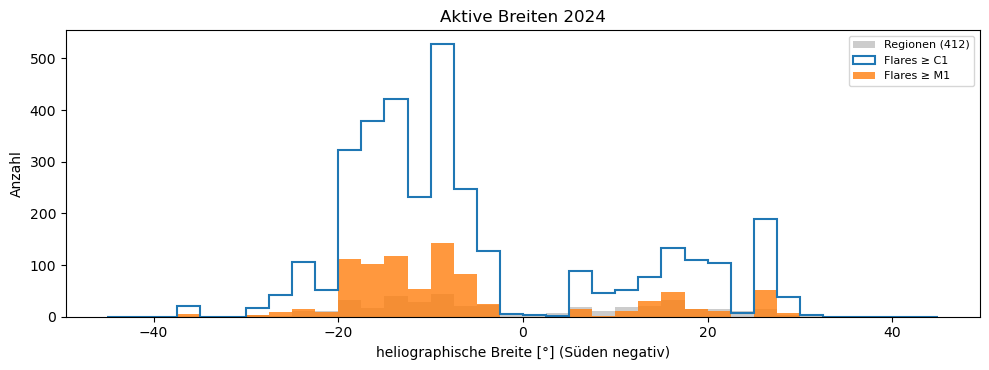

In [5]:
p = fl[ok]
for lo, name in ((1e-6, "C und stärker"), (1e-5, "M und stärker"), (1e-4, "X")):
    s = p[p.F >= lo]
    n_n, n_s = (s.lat > 0).sum(), (s.lat < 0).sum()
    asym = (n_n - n_s) / (n_n + n_s)
    print(f"{name:<14} n = {len(s):>4}: |Breite| Median {s.lat.abs().median():4.1f}°, mittlere 50 % "
          f"{s.lat.abs().quantile(.25):.0f}°–{s.lat.abs().quantile(.75):.0f}°;  Nord {n_n}, Süd {n_s}, "
          f"Asymmetrie {asym:+.2f} ± {2 * np.sqrt(n_n * n_s / (n_n + n_s) ** 3):.2f}")
regions = srs.drop_duplicates("reg")
print(f"Regionen {YEAR} (erste Sichtung): |Breite| Median {regions.lat.abs().median():.1f}°, "
      f"Nord {(regions.lat > 0).sum()}, Süd {(regions.lat < 0).sum()}")

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(-45, 46, 2.5)
ax.hist(regions.lat, bins=bins, color="0.8", label=f"Regionen ({len(regions)})")
ax.hist(p[p.F >= 1e-6].lat, bins=bins, histtype="step", color="tab:blue", lw=1.5, label="Flares ≥ C1")
ax.hist(p[p.F >= 1e-5].lat, bins=bins, color="tab:orange", alpha=0.8, label="Flares ≥ M1")
ax.set_xlabel("heliographische Breite [°] (Süden negativ)")
ax.set_ylabel("Anzahl")
ax.set_title(f"Aktive Breiten {YEAR}")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

##### *4. Flares aus δ-Regionen*

Wie viel häufiger erzeugen Regionen mit δ-Konfiguration Flares, und welche Regionen waren die produktivsten des Jahres?

In [6]:
p_delta = srs.mag.str.contains("Delta").mean()
print(f"Anteil der Regionstage mit δ-Klasse: {p_delta:.1%}  ({len(srs)} Regionstage)\n")
known = fl[fl.mag.notna()]
print(f"{'Klasse':<8}{'Flares':>8}{'aus δ-Regionen':>18}{'Anreicherung':>15}")
for lo, name in ((1e-6, "C"), (1e-5, "M"), (1e-4, "X")):
    s = known[(known.F >= lo) & (known.F < lo * 10)]
    q = s.mag.str.contains("Delta").mean()
    err = np.sqrt(q * (1 - q) / len(s))
    print(f"{name:<8}{len(s):>8}{q:>12.0%} ± {err:.0%}{q / p_delta:>13.1f}×")

top = (fl[fl.F >= 1e-5].groupby("noaa")
       .agg(M_und_X=("F", "size"), X=("F", lambda f: (f >= 1e-4).sum()), staerkster=("klasse", lambda c: c.iloc[np.argmax(c.map(flux))]),
            erster=("t_max", "min"), lat=("lat", "median")))
mag = srs.assign(noaa=srs.reg + 10000).groupby("noaa").agg(
    max_flaeche=("flaeche", "max"), delta_tage=("mag", lambda m: m.str.contains("Delta").sum()), tage=("mag", "size"))
top = top.join(mag).sort_values("M_und_X", ascending=False)
print(f"\nDie produktivsten Regionen (Fläche in Millionstel der Halbkugel):")
print(top.head(8).to_string(formatters={"erster": lambda t: f"{t:%Y-%m-%d}", "lat": "{:+.0f}".format}))
share = top.head(10).M_und_X.sum() / top.M_und_X.sum()
print(f"\nDie zehn produktivsten von {len(top)} Regionen mit M- oder X-Flares erzeugten {share:.0%} dieser Flares.")

Anteil der Regionstage mit δ-Klasse: 9.1%  (3102 Regionstage)

Klasse    Flares    aus δ-Regionen   Anreicherung
C           2483         32% ± 1%          3.5×
M            820         47% ± 2%          5.1×
X             51         73% ± 6%          8.0×

Die produktivsten Regionen (Fläche in Millionstel der Halbkugel):
       M_und_X   X staerkster     erster lat  max_flaeche  delta_tage  tage
noaa                                                                       
13664       64  12       X8.7 2024-05-02 -19       2400.0        10.0  13.0
13615       42   1       X1.1 2024-03-18 -13       1140.0        11.0  13.0
13663       40   5       X4.5 2024-05-01 +26        600.0         6.0  11.0
13697       34   6       X2.8 2024-05-27 -18        420.0        13.0  14.0
13842       31   4       X9.0 2024-09-29 -14       1040.0         8.0  12.0
13576       24   1       X2.5 2024-02-04 -16        740.0        11.0  13.0
13883       22   1       X2.3 2024-11-03  -6        420.0         7.

#### **Modell und Fit**

##### *5. Schmetterlingsdiagramm und Wanderung der Fleckenzonen*

Wie verschieben sich die Breiten neuer Regionen vom Ende von Zyklus 24 durch Zyklus 25, und welche Zerfallszeit ergibt das exponentielle Gesetz?

beide  n = 1331: φ0 = 24.5 ± 0.7°,  τ = 9.0 ± 0.6 Jahre
Nord   n =  644: φ0 = 23.8 ± 1.1°,  τ = 9.6 ± 1.0 Jahre
Süd    n =  687: φ0 = 25.1 ± 1.0°,  τ = 8.5 ± 0.7 Jahre

Mittlere |Breite| neuer Regionen pro Jahr:
tag        2016   2017   2018   2019   2020   2021    2022    2023    2024    2025    2026
n         98.00  50.00  21.00  11.00  26.00  88.00  191.00  272.00  312.00  281.00  169.00
mittel    10.72  10.94   8.62   8.36  20.65  20.42   19.27   16.29   14.34   13.05   12.70
unter_10   0.47   0.38   0.67   0.91   0.08   0.00    0.06    0.15    0.27    0.33    0.33


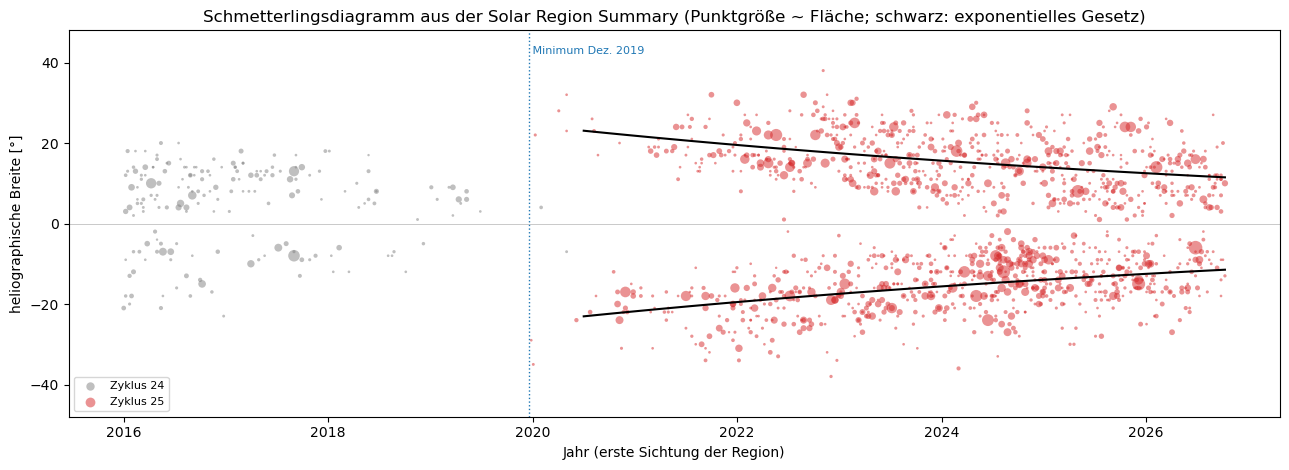

In [7]:
T_MIN = 2019.96                                       # Minimum zwischen Zyklus 24 und 25 (sun_cycle.ipynb)
first = srs_w.sort_values("tag").groupby("reg").agg(tag=("tag", "first"), lat=("lat", "first"),
                                                     flaeche=("flaeche", "max"))
first["jahr"] = first.tag.dt.year + (first.tag.dt.dayofyear - 0.5) / 365.25
first = first.dropna(subset=["lat"])

# Zyklus 25: Regionen ab Mitte 2020, als die letzten Regionen von Zyklus 24 verschwunden waren
c25 = first[first.jahr >= 2020.5]
law = lambda t, phi0, tau: phi0 * np.exp(-(t - T_MIN) / tau)
fits = {}
for name, sel in (("beide", c25), ("Nord", c25[c25.lat > 0]), ("Süd", c25[c25.lat < 0])):
    pr, cv = curve_fit(law, sel.jahr, sel.lat.abs(), p0=[25, 10])
    fits[name] = pr
    print(f"{name:<6} n = {len(sel):>4}: φ0 = {pr[0]:.1f} ± {np.sqrt(cv[0, 0]):.1f}°,  τ = {pr[1]:.1f} ± {np.sqrt(cv[1, 1]):.1f} Jahre")
print("\nMittlere |Breite| neuer Regionen pro Jahr:")
yearly = first.groupby(first.tag.dt.year).agg(n=("lat", "size"), mittel=("lat", lambda l: l.abs().mean()),
                                              unter_10=("lat", lambda l: (l.abs() < 10).mean()))
print(yearly.round(2).T.to_string())

fig, ax = plt.subplots(figsize=(13, 4.8))
# Zuordnung für die Farbe: bis Mitte 2018 alles Zyklus 24, bis Mitte 2020 nur Regionen unter 15° Breite
cyc24 = (first.jahr < 2018.5) | ((first.jahr < 2020.5) & (first.lat.abs() < 15))
for sel, col, name in ((cyc24, "0.5", "Zyklus 24"), (~cyc24, "tab:red", "Zyklus 25")):
    ax.scatter(first.jahr[sel], first.lat[sel], s=3 + first.flaeche[sel] / 15, c=col, alpha=0.5, lw=0, label=name)
ax.legend(fontsize=8, loc="lower left")
tt_fit = np.linspace(2020.5, first.jahr.max(), 100)
for sign in (1, -1):
    ax.plot(tt_fit, sign * law(tt_fit, *fits["beide"]), c="black", lw=1.5)
ax.axvline(T_MIN, c="tab:blue", ls=":", lw=1)
ax.text(T_MIN, 42, " Minimum Dez. 2019", fontsize=8, color="tab:blue")
ax.axhline(0, c="0.7", lw=0.5)
ax.set_ylim(-48, 48)
ax.set_xlabel("Jahr (erste Sichtung der Region)")
ax.set_ylabel("heliographische Breite [°]")
ax.set_title("Schmetterlingsdiagramm aus der Solar Region Summary (Punktgröße ~ Fläche; schwarz: exponentielles Gesetz)")
fig.tight_layout()
plt.show()

#### **Eigene Messung gegen den Katalog**

##### *6. Vergleich mit Hα-Positionen, SDO und HEK*

Wie genau ist die Position aus Region und Rotation, verglichen mit den Hα-Positionen derselben Ereignisse, mit dem eigenen SDO-Bild des X-Flares vom 3. Oktober 2024 und mit dem HEK-Katalog?

a) 1467 Flares haben auch eine Hα-Position (501 davon M oder X).
   Abstand eigene Position - Hα: Median 3.7°, 90 % unter 8.5°;  Breite +0.0°, Länge +1.2° im Median
   ohne Drehung auf die Flarezeit: Median 6.5°

b) X9.0 am 2024-10-03 12:18 UT in NOAA 13842:
   eigene Position (SRS + Rotation)     S15W01  (-15°, +0.9°)
   SDO, hellster Punkt in AIA 131 Å     S16W05  (-16.4°, +5.2°; sun_sdo.ipynb)
   HEK (SSW Latest Events)              S15W03  (frühere Abfrage)

c) HEK: Flares ab M5 im Jahr 2024
   eigene Liste: 133 Flares ab M5, 123 mit Position; frühere HEK-Abfrage (SSW Latest Events) für 2024: 143


   HEK nicht erreichbar (TimeoutError); später erneut ausführen


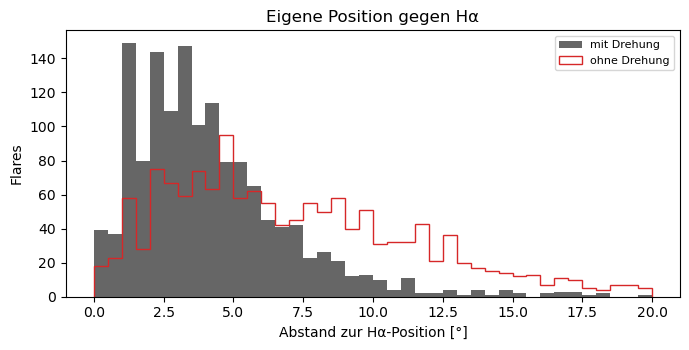

In [8]:
# a) Hα-Positionen (FLA) desselben Ereignisses
fla = events[events.typ == "FLA"].copy()
fla[["h_lat", "h_lon"]] = pd.DataFrame([parse_loc(r[0]) for r in fla.rest], index=fla.index)
m = fl.merge(fla.drop_duplicates(["tag", "ev"])[["tag", "ev", "h_lat", "h_lon"]], on=["tag", "ev"]).dropna(subset=["lat", "h_lat"])
d_lat, d_lon = m.lat - m.h_lat, m.lon - m.h_lon
d = np.hypot(d_lat, d_lon * np.cos(np.radians(m.h_lat)))
print(f"a) {len(m)} Flares haben auch eine Hα-Position ({(m.F >= 1e-5).sum()} davon M oder X).")
print(f"   Abstand eigene Position - Hα: Median {np.median(d):.1f}°, 90 % unter {np.quantile(d, 0.9):.1f}°;  "
      f"Breite {d_lat.median():+.1f}°, Länge {d_lon.median():+.1f}° im Median")
d0 = np.hypot(d_lat, (m.lon_srs - m.h_lon) * np.cos(np.radians(m.h_lat)))     # Position von 00 UT, ungedreht
print(f"   ohne Drehung auf die Flarezeit: Median {np.median(d0):.1f}°")

# b) der X-Flare vom 3. Oktober 2024 in drei Quellen
if YEAR == 2024:
    x9 = fl[(fl.tag == "2024-10-03") & (fl.F >= 1e-4)].iloc[0]
    print(f"\nb) {x9.klasse} am 2024-10-03 {x9.t_max:%H:%M} UT in NOAA {x9.noaa}:")
    print(f"   eigene Position (SRS + Rotation)     {label_ns(x9.lat, x9.lon)}  ({x9.lat:+.0f}°, {x9.lon:+.1f}°)")
    print(f"   SDO, hellster Punkt in AIA 131 Å     S16W05  (-16.4°, +5.2°; sun_sdo.ipynb)")
    print(f"   HEK (SSW Latest Events)              S15W03  (frühere Abfrage)")

# c) HEK direkt, falls erreichbar (im Oktober 2026 meist nicht)
print(f"\nc) HEK: Flares ab M5 im Jahr {YEAR}")
big = fl[fl.F >= 5e-5]
print(f"   eigene Liste: {len(big)} Flares ab M5, {big.lat.notna().sum()} mit Position"
      + ("; frühere HEK-Abfrage (SSW Latest Events) für 2024: 143" if YEAR == 2024 else ""))
socket.setdefaulttimeout(60)
try:
    from sunpy.net import attrs as a, hek
    res = hek.HEKClient().search(a.Time(f"{YEAR}-01-01", f"{YEAR}-12-31 23:59"), a.hek.EventType("FL"),
                                 a.hek.FL.GOESCls >= "M5.0", a.hek.FRM.Name == "SSW Latest Events")
    if len(res) == 0:
        raise RuntimeError("keine Einträge")
    hk = res["event_peaktime", "fl_goescls", "hgs_x", "hgs_y"].to_pandas()
    hk["t"] = pd.to_datetime(hk.event_peaktime)
    mm = pd.merge_asof(big.dropna(subset=["lat"]).sort_values("t_max"), hk.sort_values("t"), left_on="t_max",
                       right_on="t", direction="nearest", tolerance=pd.Timedelta("10min")).dropna(subset=["hgs_y"])
    dd = np.hypot(mm.lat - mm.hgs_y, (mm.lon - mm.hgs_x) * np.cos(np.radians(mm.lat)))
    print(f"   HEK: {len(hk)} Flares; {len(mm)} zugeordnet, Abstand Median {np.median(dd):.1f}°, 90 % unter {np.quantile(dd, 0.9):.1f}°")
except Exception as e:
    print(f"   HEK nicht erreichbar ({type(e).__name__}); später erneut ausführen")
finally:
    socket.setdefaulttimeout(None)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(d, bins=np.arange(0, 20.5, 0.5), color="0.4", label="mit Drehung")
ax.hist(d0, bins=np.arange(0, 20.5, 0.5), histtype="step", color="tab:red", label="ohne Drehung")
ax.set_xlabel("Abstand zur Hα-Position [°]")
ax.set_ylabel("Flares")
ax.set_title("Eigene Position gegen Hα")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Ergebnis beim Lauf vom 2026-10-12 (Jahr 2024; Schmetterlingsdiagramm bis Oktober 2026):

- **Listen:** Die Ereignislisten von 2024 enthalten 3766 Röntgenflares (C 2794, M 883, X 54), zu 95 % von GOES-16 gemessen. Das sind fast dieselben Zahlen wie in den nachbearbeiteten GOES-16-Listen in `sun_flares.ipynb` (2794 C, 864 M, 50 X); die Echtzeitklassen liegen etwas höher. Bei 8.6 % fehlt die Region, bei den M- und X-Flares nur bei 4.5 %. Für 89.7 % aller Flares ließ sich eine Position bestimmen.
- **Rotation:** Die Region NOAA 13842 stand um 00 UT bei S15E06; bis zum X9.0-Flare um 12:18 UT drehte sie sich um 6.9° auf S15W01. 115 Flares liegen nach der Drehung knapp hinter dem Westrand: Ihre Region war schon hinter dem Rand, die hohen Flare-Schleifen aber noch sichtbar.
- **Aktive Breiten:** Die Hälfte der Flares liegt zwischen 9° und 18° Breite, der Median bei 14°, bei X-Flares bei 17°. 2024 war der Süden viel aktiver: 680 der 871 M- und X-Flares kamen von der Südhalbkugel (Asymmetrie −0.56 ± 0.03), bei den Regionen war das Verhältnis nur 242 zu 170. Einige große Regionen im Süden erzeugten den Überschuss.
- **δ-Regionen:** Nur 9.1 % der Regionstage hatten eine δ-Konfiguration, aber 32 % der C-, 47 % der M- und 73 % der X-Flares kamen aus solchen Regionen, das 3.5-, 5.1- und 8.0-Fache des Erwarteten. Die produktivste Region war NOAA 13664 im Mai 2024 mit 64 M- und X-Flares, darunter 12 X, und einer Fläche von 2400 Millionstel der Halbkugel. Die zehn produktivsten von 138 Regionen erzeugten 36 % aller M- und X-Flares.
- **Schmetterlingsdiagramm:** 2019 lagen 91 % der neuen Regionen unter 10° Breite (Ende von Zyklus 24), 2020 lag die mittlere Breite plötzlich bei 21° (Beginn von Zyklus 25). Seitdem wandern die Zonen zum Äquator, bis 2026 auf 12.7°. Das exponentielle Gesetz gibt $\varphi_0 = 24.5 \pm 0.7°$ und $\tau = 9.0 \pm 0.6$ Jahre, im Norden und Süden innerhalb der Fehler gleich (23.8° und 9.6 Jahre gegen 25.1° und 8.5 Jahre). Die einzelnen Regionen streuen um etwa ±6° um die Kurve.
- **Gegen Hα:** 1467 Flares haben auch eine Hα-Position. Die eigene Position liegt im Median 3.7° davon entfernt, bei 90 % unter 8.5°; ohne die Drehung auf die Flarezeit wären es 6.5°. In der Länge liegt die eigene Position im Median 1.2° weiter westlich. Die SRS gibt den Mittelpunkt der ganzen Region an, die Hα-Position den hellsten Kern des Flares; daher kommen die einigen Grad.
- **Der X-Flare vom 3. Oktober 2024:** S15W01 aus Region und Rotation, S16W05 aus dem eigenen SDO-Bild, S15W03 bei HEK. Die Unterschiede von 2° bis 4° entsprechen der Größe der Region.
- **HEK:** Die eigene Liste hat 133 Flares ab M5 (123 mit Position), die frühere HEK-Abfrage für 2024 hatte 143. HEK antwortete auch diesmal nicht; Teil c von Schritt 6 vergleicht die Positionen, sobald der Dienst wieder läuft.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Ein Jahr im Minimum:** Setze `YEAR = 2019`. *(Vorhersage: kaum M-Flares; die wenigen Regionen liegen nahe am Äquator, weil sie noch zu Zyklus 24 gehören, und dazu kommen erste Regionen von Zyklus 25 in hohen Breiten.)*
2. **Starre Rotation:** Ersetze in Schritt 2 `omega_syn(s.lat)` durch 13.2. Wie ändert sich der Abstand zu den Hα-Positionen? *(Vorhersage: kaum, weil die Drehung innerhalb eines Tages klein ist und der Unterschied zwischen Äquator und 20° nur 0.4° pro Tag beträgt.)*
3. **Nur große Regionen:** Wiederhole Schritt 4 nur mit Regionen über 300 Millionstel Fläche. Bleibt die Anreicherung der δ-Regionen, oder erklärt sie sich durch die Größe?
4. **Lineares Gesetz:** Passe in Schritt 5 eine Gerade statt der Exponentialfunktion an. Welche Form beschreibt die frühen Jahre besser?
5. **Zyklus 24:** Setze `BUTTERFLY_START = "2008-01-01"` und `T_MIN = 2008.96` und bestimme das Gesetz für Zyklus 24 (Regionen von Anfang 2010 bis Ende 2019).

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Joys Gesetz und Hales Polaritätsregel:** Mit den Magnetogrammen von HMI (SHARP-Daten) die Neigung jeder bipolaren Region gegen den Äquator und die Reihenfolge der Polaritäten messen; die Polarität zeigt, zu welchem Zyklus eine Region gehört.
- **Ganze Zyklen:** Die Positionen der Fleckengruppen von Greenwich (1874–1976) und USAF/NOAA (seit 1977) reichen für ein Schmetterlingsdiagramm über 13 Zyklen.
- **Flare-Vorhersage:** Magnetische Klasse, Fläche und Zürich-Klasse der Region als Merkmale in einem einfachen Modell für die Wahrscheinlichkeit eines M-Flares am Folgetag, verglichen mit den Vorhersagen von NOAA.
- **Lage zur Erde:** Flares auf der Westhälfte der Scheibe sind mit der Erde magnetisch besser verbunden; ihre Teilchen erreichen die Erde häufiger. Verknüpfen mit den Protonenereignissen in denselben Listen.

#### **Referenzen**

- NOAA Space Weather Prediction Center: *Edited Solar Events Lists* und *Solar Region Summary*, archiviert bei NOAA NCEI, https://www.ngdc.noaa.gov/stp/space-weather/swpc-products/daily_reports/
- Hale, G. E., Ellerman, F., Nicholson, S. B. & Joy, A. H. (1919): *The Magnetic Polarity of Sun-Spots*, ApJ 49, 153.
- Maunder, E. W. (1904): *Note on the distribution of sun-spots in heliographic latitude, 1874–1902*, MNRAS 64, 747.
- Howard, R., Harvey, J. W. & Forgach, S. (1990): *Solar surface velocity fields determined from small magnetic features*, Solar Physics 130, 295.
- Sammis, I., Tang, F. & Zirin, H. (2000): *The Dependence of Large Flare Occurrence on the Magnetic Structure of Sunspots*, ApJ 540, 583.
- Hathaway, D. H. (2011): *A Standard Law for the Equatorward Drift of the Sunspot Zones*, Solar Physics 273, 221.
- Hathaway, D. H. (2015): *The Solar Cycle*, Living Reviews in Solar Physics 12, 4.